# Chapter 1 Introduction

## 1.Definition

An Entity that can perceive its environment through sensors and take actions through actuators to achieve goals
- Environment: external world in which the agent interacts. Inorder to let the agents see the world, cameras, microphens and other tools can collect and upload data streams via all kinds of APIs.
- Actions: Agents need to influence the environment, changing its state
- Actuators: Make the actions to be excuted in the environment
- Autonomy: Agents can make indepentdent decisions based on its preceptions and internal state to achieve it goals

### 1.1 LLM agent process
- Pllanning and reasoning: Divide the high-level task into a series of logical subtasks.
- Tool Use: When executing the plan, the agent identifies the information gap and call external tools to fill them. 
- Dynamic Adjustment: During the interaction, the agent treats feedback as new constrains and adjust subsequent actions, re-searching and recommending options that meet the new requirements.

### 1.2 Types of Agents
- Classification based on internal decision architecture: model-based agents that introduce internal models, and then to more forward-looking goal-based and utility-based agents.
- Time and reactivity: time dimension of decision making process. This perspective reveaals a core trade-off in agent design: the balance between reactivity, which pursues speed and deliberation.
- Knowledge Representation: knowledge used by agents for decision-making exists in their "minds"

## 2.Composition and operating principles of Agents

### 2.1 Task Environment Definition
- Partially observable: agent must hae memory and exploration to process partial data returned by the environment
- The results of ctions are not always deterministic
- Actions: change the sate of the environment
- Sequntiaal and dynamic: "sequential" means current actions afffect the future; "dynamic" means the environment itself may change while the agent is making decisions. This requires the agent's "perceive-think-act-observe" loop 
  

### 2.2 Agent operating Mechanism

After defining the task environment. Agent does not complete tasks in one go but interacts with the environment through a loop. 

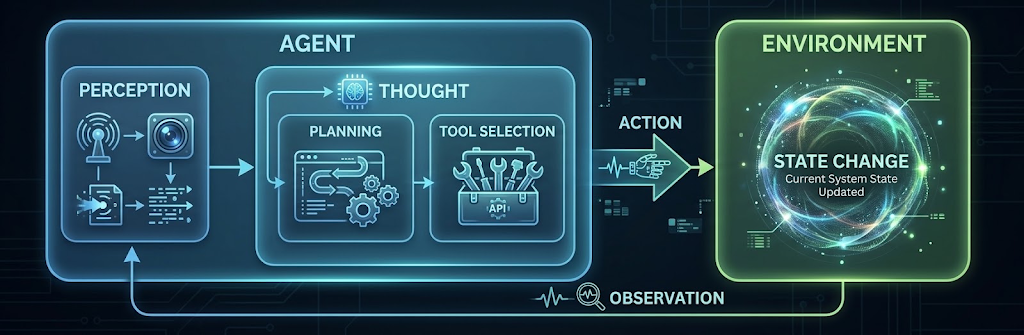

- Perception: Agent recevies input information from the environment through its sensors. This information can be either the user's initial instruction or feed back on environmental state changes caused by the previous action.
- Thought: Internal reasoning process driven by LLM
  - Planning：The agent updates its understanding of the task and environment and formulates or adjusts an action plan
  - Tool selection: The agent select the most suitable tool from its available tool library to execute the next step and determines the specific parameters
- Action: After decision-making is complete, the agent executes specific actions through its actuators. This typically manifests as calling a selected tool, thereby influencing the environment with th intent to change its state. And action is not the end of the loop

### 2.3 Agent Perception and Action

**Interaction Protocol to regulate information exchange between it and the environment**

- Thought: This is a "snapshot" of the agent's internal decision-making. It articulates in natural language how the agent analyzes the current situation, review the observation results from the previous step,engages in self-reflection and problem decomposition, and ultimately plans the next specific action. 
- Actions: This is the specific operation the agent decides to impose on the environment based on its thinking, typically expressed as a function call.

Here is a vivid, step-by-step example of an AI agent operating in this loop. Imagine a **Personal Travel Assistant Agent** whose user just asked: *"I'm flying to Tokyo tomorrow—can you check if my flight is on time and see if I need to pack an umbrella?"*

---

### Step-by-Step Agent Loop Example

#### 1. **Thought** (Internal Decision-Making & Reflection)

> *"The user is flying to Tokyo tomorrow and needs two distinct pieces of information: real-time flight status and the local weather forecast at the destination. Looking back at my instructions and the user's prompt, I cannot answer this from my static training data because flight statuses and tomorrow's weather change dynamically. I need to break this down into sequential tasks. First, I must check the flight status using the airline tracking tool. Second, I need to query the weather API for Tokyo's forecast. I will start by executing the flight status check first since it's the most urgent component."*

#### 2. **Actions** (The Executable Function Call)

Based on that reasoning, the agent triggers a concrete system operation:

```json
{
  "tool": "flight_tracker_api",
  "arguments": {
    "flight_number": "JL004",
    "date": "2026-10-27"
  }
}

```

---

### What happens next in the loop?

1. **Environment Execution:** The tool queries the airline's live database.
2. **Observation:** The environment returns data to the agent: `{"status": "On Time", "departure": "10:00 AM"}`.
3. **Next Loop (`Thought`):** The agent reviews this new observation, realizes the flight part is handled, and now generates a *new* thought to invoke the weather tool (`get_weather(city="Tokyo", date="2026-10-27")`).

## 3. Example


We can build an inteligent currency conversion system. The agent choooses an action, receives a tool result, and use that obersvtion to decide what to do next.

### 3.1 Instructoin Template
The first thing to do is driving a real LLM lies in Prompt Engineering. We need to design an "instruction template" tells the LLM what role it should play, what tools it has, and how to format its thinking and actions.

In [ ]:
AGENT_SYSTEM_PROMPT = """
You are a travel currency assistant. Help the user estimate a currency
conversion using the latest published exchange rate.

# Available tools
- get_exchange_rate(base: str, quote: str):
  Fetch the latest published exchange rate from Frankfurter.
  Returns the rate, its publication date, and the source URL.

- calculate_converted_amount(amount: str, rate: str):
  Multiply the user's amount by the rate returned by get_exchange_rate.

# Required output format
Every response must contain exactly one Thought and one Action:

Thought: [One brief sentence stating the next step]
Action: [The action to take]

An Action must be one of:
1. get_exchange_rate(base="USD", quote="EUR")
2. calculate_converted_amount(amount="200", rate="RATE_FROM_OBSERVATION")
3. Finish[Your final answer]

# Rules
- Output only one Thought–Action pair per turn.
- Put the entire Action on one line.
- Retrieve the rate before calculating. Use the actual rate in the
  Observation, not the placeholder shown above.
- Never invent an exchange rate or publication date.
- In the final answer, show the amount, rate, rate date, approximate
  converted amount, and source URL.
- Explain that the result is an estimate and excludes exchange fees.
- If a tool fails, report the failure instead of guessing.
- When you have enough information, end with Action: Finish[...].
"""

#### Step1: Install dependencies and Set credentials

In [9]:
import ast
import json
import re
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP
from getpass import getpass
from urllib.request import Request, urlopen

DEEPSEEK_API_KEY = getpass("DeepSeek API key: ")
MODEL = "deepseek-flash"

#### Step2: Template

In [10]:


AGENT_SYSTEM_PROMPT = """You are a travel currency assistant. Estimate a currency
conversion using the latest published exchange rate.

Available tools:
- get_exchange_rate(base: str, quote: str): Fetch the latest published rate,
  its publication date, and its source URL from Frankfurter.
- calculate_converted_amount(amount: str, rate: str): Multiply an amount by a
  rate previously returned by get_exchange_rate.

Every response must have exactly these two lines:
Thought: [One brief sentence stating the next step]
Action: [One action]

Valid actions:
Action: get_exchange_rate(base="USD", quote="EUR")
Action: calculate_converted_amount(amount="200", rate="RATE_FROM_OBSERVATION")
Action: Finish[Your final answer]

Only take one action per response. Fetch the rate before calculating, and
replace RATE_FROM_OBSERVATION with the actual observed rate. Never invent a
rate or publication date. In the final answer, include the amount, exchange
rate, publication date, approximate converted amount, and source URL. State
that the estimate excludes exchange fees. If a tool fails, report the
limitation rather than guessing.
"""

#### Step3: Implement the tools

In [11]:
def get_exchange_rate(base: str, quote: str) -> dict:
    base, quote = base.upper(), quote.upper()
    if not re.fullmatch(r"[A-Z]{3}", base) or not re.fullmatch(r"[A-Z]{3}", quote):
        raise ValueError("Currency codes must contain three letters.")
    if base == quote:
        raise ValueError("Choose two different currencies.")

    url = f"https://api.frankfurter.dev/v2/rate/{base.lower()}/{quote.lower()}"
    request = Request(url, headers={"Accept": "application/json"})
    with urlopen(request, timeout=15) as response:
        data = json.load(response)
    if not isinstance(data, dict) or "rate" not in data or "date" not in data:
        raise ValueError("Unexpected exchange-rate response.")

    return {
        "base": base,
        "quote": quote,
        "rate": str(data["rate"]),
        "date": data["date"],
        "source_url": url,
    }


def calculate_converted_amount(amount: str, rate: str) -> dict:
    try:
        amount_value = Decimal(amount)
        rate_value = Decimal(rate)
    except InvalidOperation as exc:
        raise ValueError("Amount and rate must be numbers.") from exc
    if not amount_value.is_finite() or not rate_value.is_finite():
        raise ValueError("Amount and rate must be finite.")
    if amount_value < 0 or rate_value <= 0:
        raise ValueError("Amount must be nonnegative and rate positive.")

    converted = (amount_value * rate_value).quantize(
        Decimal("0.01"), rounding=ROUND_HALF_UP
    )
    return {
        "amount": str(amount_value),
        "rate": str(rate_value),
        "converted_amount": str(converted),
    }

#### Step4 :Register tools and call DeepSeek

In [12]:
TOOLS = {
    "get_exchange_rate": (get_exchange_rate, {"base", "quote"}),
    "calculate_converted_amount": (
        calculate_converted_amount, {"amount", "rate"}
    ),
}


def call_deepseek(messages: list[dict]) -> str:
    payload = json.dumps({
        "model": MODEL,
        "messages": messages,
        "stream": False,
        "thinking": {"type": "disabled"},
    }).encode("utf-8")
    request = Request(
        "https://api.deepseek.com/chat/completions",
        data=payload,
        headers={
            "Authorization": f"Bearer {DEEPSEEK_API_KEY}",
            "Content-Type": "application/json",
        },
        method="POST",
    )
    with urlopen(request, timeout=90) as response:
        data = json.load(response)
    return data["choices"][0]["message"]["content"] or ""

#### Step5 Parse the Action

In [13]:
def parse_action(action: str) -> tuple[str, dict]:
    if action.startswith("Finish[") and action.endswith("]"):
        return "Finish", {"answer": action[len("Finish["):-1]}

    node = ast.parse(action, mode="eval").body
    if not isinstance(node, ast.Call) or not isinstance(node.func, ast.Name):
        raise ValueError("Action must be a tool call or Finish[...].")
    if node.args or node.func.id not in TOOLS:
        raise ValueError("Unknown tool or positional arguments.")

    arguments = {}
    for keyword in node.keywords:
        if (keyword.arg is None or keyword.arg in arguments
                or not isinstance(keyword.value, ast.Constant)
                or not isinstance(keyword.value.value, str)):
            raise ValueError("Use distinct, quoted keyword arguments.")
        arguments[keyword.arg] = keyword.value.value

    if set(arguments) != TOOLS[node.func.id][1]:
        raise ValueError("Tool arguments do not match the signature.")
    return node.func.id, arguments

#### Step6 Implement the agent loop

In [14]:
def run_agent(user_request: str, max_steps: int = 6) -> None:
    if not DEEPSEEK_API_KEY:
        raise ValueError("Enter a DeepSeek API key in Step 1.")

    messages = [
        {"role": "system", "content": AGENT_SYSTEM_PROMPT},
        {"role": "user", "content": user_request},
    ]
    observed_rate = None
    calculated_result = None

    for step in range(1, max_steps + 1):
        try:
            output = call_deepseek(messages).strip()
        except Exception as exc:
            print(f"DeepSeek request failed: {type(exc).__name__}: {exc}")
            return
        messages.append({"role": "assistant", "content": output})
        lines = [line.strip() for line in output.splitlines() if line.strip()]

        try:
            if (len(lines) != 2 or not lines[0].startswith("Thought: ")
                    or not lines[1].startswith("Action: ")):
                raise ValueError("Use one Thought line and one Action line.")
            action_name, arguments = parse_action(lines[1][len("Action: "):])
            print(f"\n--- Step {step} ---\n{lines[0]}\n{lines[1]}")

            if action_name == "Finish":
                if observed_rate is None or calculated_result is None:
                    raise ValueError("Fetch a rate and calculate before finishing.")
                print("\nFinal answer:", arguments["answer"])
                return

            if action_name == "calculate_converted_amount":
                if observed_rate is None:
                    raise ValueError("Fetch an exchange rate first.")
                if arguments["rate"] != observed_rate["rate"]:
                    raise ValueError("Use the exact observed rate.")

            observation = TOOLS[action_name][0](**arguments)
            if action_name == "get_exchange_rate":
                observed_rate = observation
                calculated_result = None
            else:
                calculated_result = observation
        except Exception as exc:
            observation = {"error": f"{type(exc).__name__}: {exc}"}

        print("Observation:", observation)
        messages.append({
            "role": "user",
            "content": "Observation: " + json.dumps(observation, ensure_ascii=False),
        })

    print("\nStopped after reaching the maximum number of steps.")

#### Step7 Check the local parser and calculation

In [15]:
assert parse_action('get_exchange_rate(base="USD", quote="EUR")') == (
    "get_exchange_rate", {"base": "USD", "quote": "EUR"}
)
assert calculate_converted_amount("200", "0.86")["converted_amount"] == "172.00"
print("Local checks passed.")

Local checks passed.


In [16]:
run_agent("I have 200 USD. About how many euros is that?")


--- Step 1 ---
Thought: I need the latest published USD to EUR exchange rate before converting.
Action: get_exchange_rate(base="USD", quote="EUR")
Observation: {'base': 'USD', 'quote': 'EUR', 'rate': '0.8918', 'date': '2026-10-26', 'source_url': 'https://api.frankfurter.dev/v2/rate/usd/eur'}

--- Step 2 ---
Thought: Now I'll multiply the 200 USD by the observed rate.
Action: calculate_converted_amount(amount="200", rate="0.8918")
Observation: {'amount': '200', 'rate': '0.8918', 'converted_amount': '178.36'}

--- Step 3 ---
Thought: I have the rate, date, source, and converted amount, so I can give the final estimate.
Action: Finish[200 USD is approximately 178.36 EUR at the latest published rate of 0.8918 (USD→EUR), published 2026-10-26. Source: https://api.frankfurter.dev/v2/rate/usd/eur. This estimate excludes exchange fees.]

Final answer: 200 USD is approximately 178.36 EUR at the latest published rate of 0.8918 (USD→EUR), published 2026-10-26. Source: https://api.frankfurter.dev/